# 26 - Le théorème des trois carrés de Legendre

*Essai de théorie des nombres* (Legendre, 1798) ; *Disquisitiones Arithmeticae* art. 291 (Gauss, 1801).

Le carnet [15](15-quatre-carres-lagrange.ipynb) a établi que **tout** entier est somme de quatre carrés (Lagrange), avec la formule exacte de Jacobi pour $r_4(n)$. Trois carrés suffisent-ils ? Legendre — et Gauss, premier avec une démonstration complète — y répondent par un critère d'une économie remarquable :

> $n = x^2 + y^2 + z^2$ est soluble en entiers **si et seulement si** $n \neq 4^a(8b+7)$.

Une obstruction **purement locale** — un résidu modulo 8, qui se creuse modulo $2^{2a+3}$ quand $4^a$ divise $n$ — décide d'une question globale. C'est le cas ternaire explicite du principe local-global traité au carnet 24 (Hasse-Minkowski, PR ouverte à la rédaction de ce carnet) : pour la forme $x^2+y^2+z^2$, toute l'obstruction vit en la seule place $p = 2$.

**Le fil calculatoire**, en arithmétique `stdlib` pure (`math.isqrt`, `fractions`) :

1. **Le critère mesuré** — force brute contre $4^a(8b+7)$ sur $n \le 5000$ : zéro écart ; un sixième des entiers exactement du côté des exclus.
2. **La profondeur de l'obstruction** — le plus petit $k$ où la solvabilité modulo $2^k$ échoue : exactement $2a+3$, mesuré sur des familles entières.
3. **L'instrument $r_3(n)$** — représentations ordonnées avec signes, validé contre OEIS A005875 — et ses deux pièges de balayage, attrapés par la mesure.
4. **Gauss et Hurwitz** — $r_3(n)$ exprimé par les nombres de classes des carnets [12](12-formes-quadratiques-binaires-nombre-classes.ipynb) et [14](14-formes-quadratiques-composition-gauss.ipynb).
5. **Exemples guidés résolus et exercices** — trois paires, dans la convention de la série.

*Sources primaires* : Legendre (1798), Gauss (1801) art. 291, Hurwitz (1885) ; Serre, *A Course in Arithmetic* ch. IV pour la parenté local-global.

## 1. Le critère, mesuré contre la force brute

Le théorème affirme une équivalence exacte entre une condition de congruence et l'existence d'une solution entière. Avant toute théorie, on la **mesure** : le critère — `excluded(n)`, par dégraissage des puissances de 4 puis test du résidu modulo 8 — contre la recherche exhaustive `solvable_brute(n)` avec $z \le y \le x$, entiers par entiers.

La sonde confronte les deux camps sur $n \le 5000$, dresse la liste des petits exclus, et mesure la densité des exclus jusqu'à $10^5$.

In [1]:
import math

def excluded(n):
    # n est-il de la forme 4^a (8b+7) ? On degraisse les puissances de 4...
    m = n
    while m % 4 == 0:
        m //= 4
    # ...puis on regarde le residu modulo 8.
    return m % 8 == 7

def solvable_brute(n):
    # Recherche exhaustive avec z <= y <= x : rend le premier temoin trouve.
    x = 0
    while x * x <= n:
        r = n - x * x
        y = x
        while 2 * y * y <= r:
            z2 = r - y * y
            z = math.isqrt(z2)
            if z * z == z2:
                return (x, y, z)
            y += 1
        x += 1
    return None

N = 5000
mismatch = [n for n in range(1, N + 1) if excluded(n) != (solvable_brute(n) is None)]
exclus = [n for n in range(1, N + 1) if excluded(n)]
print(f"brute vs critere sur n = 1..{N} : ecarts = {len(mismatch)}")
print(f"exclus < 100 : {[n for n in exclus if n < 100]}")

M = 100000
dens = sum(1 for n in range(1, M + 1) if excluded(n)) / M
print(f"densite des exclus jusqu'a {M} : {dens:.6f}   (1/6 = {1/6:.6f})")

brute vs critere sur n = 1..5000 : ecarts = 0
exclus < 100 : [7, 15, 23, 28, 31, 39, 47, 55, 60, 63, 71, 79, 87, 92, 95]
densite des exclus jusqu'a 100000 : 0.166640   (1/6 = 0.166667)


### Lecture du résultat

- **Zéro écart sur 5000 entiers** : le critère n'est pas une heuristique, c'est une équivalence exacte — chaque exclu est infranchissable par la force brute, chaque non-exclu a son témoin.
- La liste des petits exclus se lit directement dans le critère : $7 = 8\cdot0+7$, $15 = 8\cdot1+7$, $23 = 8\cdot2+7$, $28 = 4\cdot7$, $31 = 8\cdot3+7$, $60 = 4\cdot15$, $92 = 4\cdot23$...
- La **densité des exclus converge vers 1/6** (mesurée à 0,166640 pour $10^5$) : un entier sur six échappe aux trois carrés.

Reste la question que la force brute ne pose pas : **pourquoi** ces entiers-là ? La section suivante montre que l'obstruction est *locale* — purement 2-adique — et que sa profondeur se creuse avec la puissance de 4 qui divise $n$.

## 2. La profondeur de l'obstruction : modulo $2^k$, elle se creuse

Pour qu'une équation diophantienne ait une solution entière, il faut *a minima* une solution modulo tout $m$. On mesure cette obstruction locale directement : la solvabilité de $x^2 + y^2 + z^2 \equiv n \pmod{2^k}$.

Le triple balayage naïf ($2^{3k}$ itérations) est hors de portée dès $k = 13$ ; l'instrument ci-dessous énumère l'ensemble $S_k$ des **carrés** modulo $2^k$ (par symétrie $x^2 = (-x)^2$, une demi-passe suffit), puis balaie les paires $(s_1, s_2) \in S_k^2$ en testant si $n - s_1 - s_2 \in S_k$.

La mesure cherche, pour la famille des exclus $n_a = 7 \cdot 4^a$ ($a = 0, \ldots, 5$), le **plus petit $k$ où la solvabilité échoue**, et le confronte à la loi conjecturée $k_{\min} = 2a + 3$ ; des témoins non exclus servent de contrôle.

In [2]:
_carres_cache = {}

def carres_mod2k(k):
    # Ensemble des carres modulo 2^k (symetrie x^2 = (-x)^2).
    if k not in _carres_cache:
        m = 1 << k
        _carres_cache[k] = {(i * i) % m for i in range(m // 2 + 1)}
    return _carres_cache[k]

def solvable_mod2k(n, k):
    # x^2 + y^2 + z^2 = n (mod 2^k) ? Paires de carres + appartenance.
    m = 1 << k
    S = carres_mod2k(k)
    for s1 in S:
        r = (n - s1) % m
        for s2 in S:
            if (r - s2) % m in S:
                return True
    return False

def plus_petit_k_refusant(n, kmax):
    # Premier k ou la solvabilite mod 2^k echoue (None si aucun jusqu'a kmax).
    for k in range(1, kmax + 1):
        if not solvable_mod2k(n, k):
            return k
    return None

print("famille 7*4^a : plus petit k ou la solvabilite mod 2^k echoue")
print(f"{'a':>2} {'n = 7*4^a':>10} {'k_min':>6} {'2a+3':>5}")
for a in range(6):
    n = 7 * 4**a
    kmin = plus_petit_k_refusant(n, 2 * a + 5)
    print(f"{a:>2} {n:>10} {str(kmin):>6} {2*a+3:>5}")

print()
print("controles (non exclus) : solvables pour tout k <= 14 ?")
for n in [3, 5, 6, 14, 33]:
    kmin = plus_petit_k_refusant(n, 14)
    print(f"n = {n:>3}  exclu = {str(excluded(n)):>5}  k_min = {kmin}")

famille 7*4^a : plus petit k ou la solvabilite mod 2^k echoue
 a  n = 7*4^a  k_min  2a+3
 0          7      3     3
 1         28      5     5
 2        112      7     7
 3        448      9     9
 4       1792     11    11


 5       7168     13    13

controles (non exclus) : solvables pour tout k <= 14 ?
n =   3  exclu = False  k_min = None
n =   5  exclu = False  k_min = None
n =   6  exclu = False  k_min = None
n =  14  exclu = False  k_min = None
n =  33  exclu = False  k_min = None


### Lecture du résultat

- Le plus petit $k$ refusant $7 \cdot 4^a$ est **exactement $2a + 3$**, six fois sur six : l'obstruction modulo 8 pour $a = 0$ devient une obstruction modulo $2^{2a+3}$ quand $4^a$ divise $n$. La profondeur est **mesurée**, pas posée.
- Les contrôles confirment la partition : tout $n$ non exclu reste soluble modulo $2^k$ pour **tout** $k$ testé (jusqu'à 14).
- Le **dégraissage des puissances de 4** du critère cesse d'être une bizarrerie d'énoncé : c'est une conséquence. Si $n = 4m$ et $x^2+y^2+z^2 = n$, alors $x, y, z$ sont tous pairs (un carré vaut $0$ ou $1$ mod 4 ; trois carrés sommant à $0$ mod 4 sont tous $0$), donc $m$ lui-même est somme de trois carrés — la solvabilité de $n$ et celle de $n/4$ sont équivalentes. L'obstruction remonte ainsi de $m = n/4^a$ : $m \equiv 7 \pmod 8$ refuse dès $k = 2a + 3$.
- Le critère de Legendre est donc un **principe local-global explicite** : pour cette forme, toute l'obstruction vit en la seule place $p = 2$ — le cas ternaire du cadre général de Hasse-Minkowski (carnet 24, PR ouverte).

## 3. L'instrument $r_3(n)$ — et ses deux pièges

Compter les représentations ordonnées avec signes,

$$r_3(n) = \#\{(x, y, z) \in \mathbb{Z}^3 : x^2 + y^2 + z^2 = n\}$$

(OEIS **A005875**), est l'instrument quantitatif du théorème — la section 4 l'exprimera par les nombres de classes. Le balayage naturel à deux boucles ($x$, $y$ explicites, $z$ implicite via `isqrt`) réserve **deux pièges** :

1. **`break` sur carré négatif** : pour $x$ fixé, $n - x^2 - y^2$ n'est **pas monotone en $y$** sur $[-m, m]$ (il décroît puis recroît) ; interrompre le balayage dès qu'il devient négatif à $y = -m$ saute des solutions aux $y$ centraux.
2. **Multiplicité des signes de $z$** : le balayage ne voit que $z = +\sqrt{\cdots}$ ; pour $z > 0$, le point $(x, y, -z)$ compte aussi.

On construit l'instrument **correct**, on le valide contre A005875, puis on mesure l'écart des deux variantes fautives — la leçon de méthode vaut pour toute la série.

In [3]:
def r3(n):
    # Nombre de representations ordonnees avec signes (A005875).
    if excluded(n):
        return 0
    c = 0
    m = math.isqrt(n)
    for x in range(-m, m + 1):
        for y in range(-m, m + 1):
            z2 = n - x * x - y * y
            if z2 < 0:
                continue               # piege 1 : jamais break, y^2 n'est pas monotone en y
            z = math.isqrt(z2)
            if z * z == z2:
                c += 2 if z > 0 else 1  # piege 2 : +z et -z quand z > 0
    return c

A005875 = [6, 12, 8, 6, 24, 24, 0, 12, 30, 24, 24, 8, 24, 48, 0, 6, 48, 36, 24, 24]
seq = [r3(n) for n in range(1, 21)]
print(f"r_3(1..20)   = {seq}")
print(f"OEIS A005875 = {A005875}")
print(f"concordance  = {seq == A005875}")

# --- les deux variantes fautives, mesurees ---

def r3_bug_signes(n):
    # Oublie -z : chaque z > 0 ne compte qu'une fois.
    if excluded(n):
        return 0
    c = 0
    m = math.isqrt(n)
    for x in range(-m, m + 1):
        for y in range(-m, m + 1):
            z2 = n - x * x - y * y
            if z2 < 0:
                continue
            z = math.isqrt(z2)
            if z * z == z2:
                c += 1
    return c

def r3_bug_break(n):
    # break au lieu de continue sur z2 < 0.
    if excluded(n):
        return 0
    c = 0
    m = math.isqrt(n)
    for x in range(-m, m + 1):
        for y in range(-m, m + 1):
            z2 = n - x * x - y * y
            if z2 < 0:
                break
            z = math.isqrt(z2)
            if z * z == z2:
                c += 2 if z > 0 else 1
    return c

print()
print(f"n = 1 : correct {r3(1)}, sans les signes de z {r3_bug_signes(1)}, avec break {r3_bug_break(1)}")
premier_ecart = next(n for n in range(1, 60) if r3_bug_break(n) != r3(n))
print(f"variante break : premier ecart en n = {premier_ecart} "
      f"({r3_bug_break(premier_ecart)} au lieu de {r3(premier_ecart)})")

r_3(1..20)   = [6, 12, 8, 6, 24, 24, 0, 12, 30, 24, 24, 8, 24, 48, 0, 6, 48, 36, 24, 24]
OEIS A005875 = [6, 12, 8, 6, 24, 24, 0, 12, 30, 24, 24, 8, 24, 48, 0, 6, 48, 36, 24, 24]
concordance  = True

n = 1 : correct 6, sans les signes de z 5, avec break 4
variante break : premier ecart en n = 1 (4 au lieu de 6)


### Lecture du résultat

- L'instrument correct **reproduit A005875 exactement** sur $n \le 20$ : les exclus valent 0 ($n = 7, 15$), les autres croissent irrégulièrement — c'est cette irrégularité que la loi de Gauss-Hurwitz explique à la section 4.
- Les deux pièges divergent **dès $n = 1$** : la variante sans les signes de $z$ rend 5 au lieu de 6 (elle perd $(0, 0, -1)$), la variante `break` rend 4 (elle perd en plus $(1, 0, 0)$ et $(-1, 0, 0)$, avalés par l'interruption du balayage à $y = -1$).
- Leçon de méthode : un instrument de comptage se **valide contre une référence indépendante** avant de servir — OEIS ici, les tables $h(D)$ pour les carnets 12 et 14.

## 4. Gauss et Hurwitz : les nombres de classes comptent les représentations

Gauss (*Disquisitiones*, art. 291) relie le nombre de représentations aux **classes de formes binaires quadratiques** — les objets des carnets [12](12-formes-quadratiques-binaires-nombre-classes.ipynb) et [14](14-formes-quadratiques-composition-gauss.ipynb). La forme nettoyée par Hurwitz (1885) :

$$
r_3(n) = \begin{cases}
12\,H(4n) & n \equiv 1, 2 \pmod 4 \\
24\,H(n) & n \equiv 3 \pmod 8 \\
0 & n \equiv 7 \pmod 8 \\
r_3(n/4) & 4 \mid n
\end{cases}
$$

où $H(N)$ est le **nombre de classes de Hurwitz** : le décompte pondéré des formes réduites $(a, b, c)$ de discriminant $b^2 - 4ac = -N$ — la réduction des carnets 12, $|b| \le a \le c$ avec $b \ge 0$ sur les bords $|b| = a$ ou $a = c$. La pondération se lit sur la partie **primitive** de la forme : si $g$ est le contenu (pgcd des coefficients), la forme $g \cdot (a', b', c')$ hérite du poids de sa primitive de discriminant $-N/g^2$ — poids $1/3$ pour le discriminant $-3$, $1/2$ pour $-4$ (les deux discriminants à formes automorphes exceptionnelles), $1$ sinon.

**Copie pédagogique déclarée** : l'énumération des formes réduites est réécrite ici en stdlib pur plutôt qu'importée — les carnets 12 et 14 sont des carnets autonomes, pas une librairie importable ; la série n'expose pas de module à consommer. Tout en `fractions.Fraction`, aucune arithmétique flottante.

La mesure : construire $H$, appliquer la dispatch, et confronter à l'instrument $r_3$ validé en section 3.

In [4]:
from fractions import Fraction
from math import gcd, isqrt

def formes_reduites(N):
    # Formes (a, b, c) entieres reduites de discriminant -N
    # (reduction des carnets 12 : -a < b <= a <= c, b >= 0 sur les bords).
    formes = []
    for a in range(1, isqrt(N // 3) + 1):
        for b in range(-a + 1, a + 1):
            num = b * b + N
            if num % (4 * a):
                continue
            c = num // (4 * a)
            if c < a:
                continue
            if b < 0 and (a == c or abs(b) == a):
                continue   # bord de reduction : un seul representant par orbite
            formes.append((a, b, c))
    return formes

def hurwitz_H(N):
    # Nombre de classes de Hurwitz : formes reduites de disc. -N, poids Fraction.
    total = Fraction(0)
    for (a, b, c) in formes_reduites(N):
        g = gcd(gcd(a, b), c)
        d_prim = N // (g * g)           # discriminant de la partie primitive
        if d_prim == 3:
            w = Fraction(1, 3)          # forme automorphe exceptionnelle
        elif d_prim == 4:
            w = Fraction(1, 2)
        else:
            w = Fraction(1)
        total += w
    return total

def r3_par_classes(n):
    # La dispatch de Gauss-Hurwitz, apres degraissage des puissances de 4.
    while n % 4 == 0:
        n //= 4
    if n % 8 == 7:
        return 0
    if n % 8 == 3:
        return 24 * hurwitz_H(n)
    return 12 * hurwitz_H(4 * n)        # n = 1 ou 2 mod 4

ecarts = [n for n in range(1, 41) if r3_par_classes(n) != r3(n)]
print(f"confrontation r_3 vs dispatch de Gauss-Hurwitz sur n = 1..40 : ecarts = {len(ecarts)}")
print()
print(f"{'n':>3} {'r_3(n)':>7} {'classes':>8}  detail")
for n in range(1, 13):
    m = n
    while m % 4 == 0:
        m //= 4
    if m % 8 == 7:
        detail = "0 (exclu)"
    elif m % 8 == 3:
        detail = f"24*H({m})  avec H = {hurwitz_H(m)}"
    else:
        detail = f"12*H(4*{m})  avec H = {hurwitz_H(4 * m)}"
    print(f"{n:>3} {r3(n):>7} {r3_par_classes(n):>8}  {detail}")

confrontation r_3 vs dispatch de Gauss-Hurwitz sur n = 1..40 : ecarts = 0

  n  r_3(n)  classes  detail
  1       6        6  12*H(4*1)  avec H = 1/2
  2      12       12  12*H(4*2)  avec H = 1
  3       8        8  24*H(3)  avec H = 1/3
  4       6        6  12*H(4*1)  avec H = 1/2
  5      24       24  12*H(4*5)  avec H = 2
  6      24       24  12*H(4*6)  avec H = 2
  7       0        0  0 (exclu)
  8      12       12  12*H(4*2)  avec H = 1
  9      30       30  12*H(4*9)  avec H = 5/2
 10      24       24  12*H(4*10)  avec H = 2
 11      24       24  24*H(11)  avec H = 1
 12       8        8  24*H(3)  avec H = 1/3


### Lecture du résultat

- **Concordance parfaite sur $n \le 40$** : la dispatch reproduit l'instrument exhaustif, signes compris. Le cas $n = 9$ expose la subtilité des poids : $H(36) = 5/2$ — la forme $(3, 0, 3)$, imprimitive de contenu 3, hérite du poids $1/2$ de sa primitive $(1, 0, 1)$ de discriminant $-4$ — et $12 \times 5/2 = 30 = r_3(9)$.
- Les coefficients 12 et 24 absorbent les poids $1/2$ et $1/3$ : tant qu'aucune forme à stabilisateur n'intervient, $r_3(n)$ est multiple de 12 (ou 24) ; dès qu'une intervient, la valeur casse la multiplicité — $r_3(3) = 24 \times \tfrac{1}{3} = 8$, $r_3(9) = 12 \times \tfrac{5}{2} = 30$.
- Le pont est complet : une fonction en apparence irrégulière ($r_3$) est **exactement** un nombre de classes — l'objet des carnets 12 et 14. La dichotomie de Legendre (section 1) et la profondeur $2a+3$ (section 2) deviennent des lignes de la dispatch : annulation pour $n \equiv 7 \pmod 8$, récursion $r_3(n/4)$ pour le dégraissage.

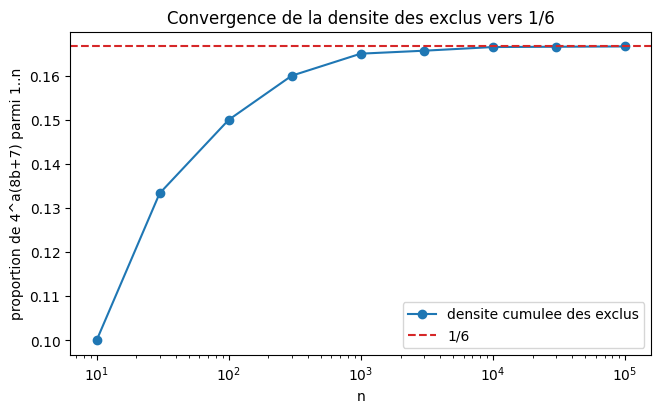

In [5]:
import matplotlib.pyplot as plt

paliers = [10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000]
cumules = []
total_exclus = 0
vus = 0
for x in paliers:
    total_exclus += sum(1 for n in range(vus + 1, x + 1) if excluded(n))
    vus = x
    cumules.append(total_exclus / x)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(paliers, cumules, 'o-', color='tab:blue', label='densite cumulee des exclus')
ax.axhline(1/6, color='tab:red', ls='--', label='1/6')
ax.set_xscale('log')
ax.set_xlabel('n')
ax.set_ylabel('proportion de 4^a(8b+7) parmi 1..n')
ax.set_title("Convergence de la densite des exclus vers 1/6")
ax.legend()
plt.show()

### Lecture du résultat

La densité cumulée s'installe sur **1/6** : chaque couche $4^a(8b+7)$ est une progression arithmétique de raison $8 \cdot 4^a$, donc de densité $1/(8 \cdot 4^a)$, et les couches disjointes se somment en

$$\frac{1}{8}\left(1 + \frac{1}{4} + \frac{1}{16} + \cdots\right) = \frac{1}{8} \cdot \frac{4}{3} = \frac{1}{6}.$$

Un sixième des entiers exactement vit du côté des exclus — les cinq sixièmes restants sont exactement les sommes de trois carrés. La mesure rejoint l'énoncé : le critère partitionne $\mathbb{N}$ en deux mondes de proportions connues.

## 5. Exemples guidés résolus et exercices

Trois paires, dans la convention de la série : chaque **exemple guidé** est résolu et commenté, et l'**exercice** qui le suit immédiatement réutilise le même instrument sur une question nouvelle — à compléter (`TODO étudiant`), exécutable sans erreur (la sortie attendue d'un exercice non complété est `None`).

### Exemple guidé 1 — Nombres de Mersenne : jamais trois carrés

**Question.** Les nombres de Mersenne $2^p - 1$ ($p \ge 3$) sont-ils sommes de trois carrés ?

**Instrument.** `excluded` (le critère) et `r3` (le compteur validé section 3) : pour $p = 3, \ldots, 12$, calculer les deux et vérifier l'accord — exclu implique $r_3 = 0$.

**Réponse attendue.** $2^p - 1 \equiv 7 \pmod 8$ pour tout $p \ge 3$, donc **tous exclus** : le critère prédit zéro représentation, et le compteur le confirme sans exception.

In [6]:
def mersenne_trois_carres(pmax):
    # Pour chaque p de 3 a pmax : n = 2^p - 1, critere et compteur.
    return [(p, 2**p - 1, excluded(2**p - 1), r3(2**p - 1)) for p in range(3, pmax + 1)]

print(f"{'p':>3} {'n = 2^p-1':>10} {'exclu':>6} {'r_3(n)':>7}")
for p, n, ex, r in mersenne_trois_carres(12):
    print(f"{p:>3} {n:>10} {str(ex):>6} {r:>7}")

accord = all(ex and r == 0 for _, _, ex, r in mersenne_trois_carres(12))
print(f"accord critere-compteur (exclu => r_3 = 0) : {accord}")

  p  n = 2^p-1  exclu  r_3(n)
  3          7   True       0
  4         15   True       0
  5         31   True       0
  6         63   True       0
  7        127   True       0
  8        255   True       0
  9        511   True       0
 10       1023   True       0
 11       2047   True       0
 12       4095   True       0
accord critere-compteur (exclu => r_3 = 0) : True


### Exercice 1 — Jamais trois, toujours quatre

Les exclus de Legendre restent **sommes de quatre carrés** (Lagrange, carnet [15](15-quatre-carres-lagrange.ipynb)), avec la formule exacte de Jacobi établie là-bas :

$$r_4(n) = 8 \sum_{\substack{d \mid n \\ 4 \nmid d}} d.$$

Compléter `exo1_jamais_trois_toujours_quatre` : pour chaque exclu $n \le 100$, rendre le triplet $(n, r_3(n), r_4(n))$ et vérifier la double assertion $r_3(n) = 0$ **et** $r_4(n) > 0$.

- **Étape 1** — énumérer les exclus $n \le 100$ (la liste figure en section 1).
- **Étape 2** — calculer $r_4(n)$ par la formule de Jacobi : diviseurs $d$ de $n$ tels que $4 \nmid d$, sommés puis multipliés par 8.
- **Étape 3** — vérifier la double assertion sur toute la liste, et rendre les triplets.

In [7]:
def exo1_jamais_trois_toujours_quatre(limite):
    # TODO etudiant : (n, r_3(n), r_4(n)) pour chaque exclu n <= limite, assertion verifiee.
    # Indice : r_4(n) = 8 * somme des diviseurs d de n tels que 4 ne divise pas d.
    # Etape 1 : exclus n <= limite via excluded().
    # Etape 2 : diviseurs par balayage jusqu'a isqrt(n) (paires d et n//d).
    # Etape 3 : verifier r_3 = 0 et r_4 > 0 pour chacun ; rendre la liste des triplets.
    return None  # TODO etudiant

resultat_exo1 = exo1_jamais_trois_toujours_quatre(100)
print("Exercice 1 a completer (resultat actuel : %r)" % (resultat_exo1,))

Exercice 1 a completer (resultat actuel : None)


### Exemple guidé 2 — La profondeur de l'obstruction pour la famille $15 \cdot 4^a$

**Question.** La section 2 a mesuré $k_{\min} = 2a + 3$ pour $7 \cdot 4^a$. La loi tient-elle pour une autre famille d'exclus, $15 \cdot 4^a$ ?

**Instrument.** `plus_petit_k_refusant` : pour $a = 0, \ldots, 5$, premier $k$ refusant $n_a = 15 \cdot 4^a$, confronté à $2a + 3$.

**Réponse attendue.** $15 = 8 + 7$ : même motif, même profondeur — $k_{\min} = 2a + 3$ sur toute la famille (le témoin $a = 1$, $n = 60$, figurait déjà parmi les exclus de la section 1).

In [8]:
print(f"{'a':>2} {'n = 15*4^a':>10} {'k_min':>6} {'2a+3':>5}")
for a in range(6):
    n = 15 * 4**a
    kmin = plus_petit_k_refusant(n, 2 * a + 5)
    print(f"{a:>2} {n:>10} {str(kmin):>6} {2*a+3:>5}")

verdict = all(plus_petit_k_refusant(15 * 4**a, 2 * a + 5) == 2 * a + 3 for a in range(6))
print(f"famille 15*4^a : k_min = 2a+3 partout : {verdict}")

 a n = 15*4^a  k_min  2a+3
 0         15      3     3
 1         60      5     5
 2        240      7     7
 3        960      9     9
 4       3840     11    11
 5      15360     13    13


famille 15*4^a : k_min = 2a+3 partout : True


### Exercice 2 — Deux familles de part et d'autre du critère

Deux questions sur le même instrument `plus_petit_k_refusant` :

1. Pour la famille des exclus $n_a = 23 \cdot 4^a$ ($23 = 8 \cdot 2 + 7$), $a = 0, \ldots, 4$ : la loi $k_{\min} = 2a + 3$ tient-elle ?
2. **Réciproque** — pour les non exclus $n_a = 3 \cdot 4^a$ ($a = 0, \ldots, 4$) : montrer qu'aucun $k \le 14$ ne refuse, l'absence d'obstruction locale 2-adique est totale.

- **Étape 1** — balayer les deux familles avec `plus_petit_k_refusant` (bornes $2a + 5$ et $14$).
- **Étape 2** — confronter à $2a + 3$ pour la première, à `None` pour la seconde.
- **Étape 3** — rendre les deux listes.

In [9]:
def exo2_profondeurs_familles():
    # TODO etudiant : rendre (liste_23, liste_3), les k_min des familles 23*4^a et 3*4^a (a = 0..4).
    # Indice : plus_petit_k_refusant(n, kmax) rend None quand aucun k <= kmax ne refuse.
    # Etape 1 : famille 23*4^a avec kmax = 2a+5, attendu 2a+3.
    # Etape 2 : famille 3*4^a (non exclue) avec kmax = 14, attendu None partout.
    # Etape 3 : rendre les deux listes.
    return None  # TODO etudiant

resultat_exo2 = exo2_profondeurs_familles()
print("Exercice 2 a completer (resultat actuel : %r)" % (resultat_exo2,))

Exercice 2 a completer (resultat actuel : None)


### Exemple guidé 3 — Le pont $12\,H(4n) = r_3(n)$ sur la classe $n \equiv 1, 2 \pmod 4$

**Question.** Vérifier la première ligne de la dispatch de Gauss-Hurwitz sur une classe de congruence entière : pour les $n \le 30$ avec $n \equiv 1, 2 \pmod 4$, $12\,H(4n) = r_3(n)$ ?

**Instrument.** `hurwitz_H` et `r3` : table complète des quinze valeurs, et compte des écarts.

**Réponse attendue.** Zéro écart — le pont tient membre à membre, y compris les valeurs non entières de $H$ (par exemple $n = 9$, $H(36) = 5/2$).

In [10]:
classe = [n for n in range(1, 31) if n % 4 in (1, 2)]
print(f"{'n':>3} {'12*H(4n)':>9} {'r_3(n)':>7}")
ecarts = 0
for n in classe:
    attendu = 12 * hurwitz_H(4 * n)
    if attendu != r3(n):
        ecarts += 1
    print(f"{n:>3} {str(attendu):>9} {r3(n):>7}")
print(f"classe n = 1, 2 mod 4, n <= 30 : ecarts = {ecarts}")

  n  12*H(4n)  r_3(n)
  1         6       6
  2        12      12
  5        24      24
  6        24      24
  9        30      30
 10        24      24
 13        24      24
 14        48      48
 17        48      48
 18        36      36
 21        48      48
 22        24      24
 25        30      30
 26        72      72
 29        72      72
 30        48      48
classe n = 1, 2 mod 4, n <= 30 : ecarts = 0


### Exercice 3 — Le pont $24\,H(n) = r_3(n)$ sur la classe $n \equiv 3 \pmod 8$

Deuxième ligne de la dispatch : pour les $n \le 100$ avec $n \equiv 3 \pmod 8$, compléter `exo3_pont_classe_3_mod_8` — vérifier $24\,H(n) = r_3(n)$ membre à membre.

- **Étape 1** — énumérer la classe ($n = 3, 11, 19, 27, \ldots$).
- **Étape 2** — pour chaque $n$, comparer $24\,H(n)$ à $r_3(n)$.
- **Étape 3** — rendre le nombre d'écarts (attendu : 0) — attention aux $H$ tiers d'entier, par exemple $H(3) = 1/3$.

In [11]:
def exo3_pont_classe_3_mod_8(limite):
    # TODO etudiant : rendre le nombre d'ecarts entre 24*H(n) et r_3(n), n <= limite, n = 3 mod 8.
    # Indice : la classe est range(3, limite + 1, 8) ; hurwitz_H(n) est une Fraction.
    # Etape 1 : enumerer la classe.
    # Etape 2 : comparer 24*hurwitz_H(n) et r3(n) pour chacun.
    # Etape 3 : compter les ecarts et rendre le total.
    return None  # TODO etudiant

resultat_exo3 = exo3_pont_classe_3_mod_8(100)
print("Exercice 3 a completer (resultat actuel : %r)" % (resultat_exo3,))

Exercice 3 a completer (resultat actuel : None)


## Conclusion

- **Le critère est exact, mesuré** : zéro écart contre la force brute sur $n \le 5000$ ; un sixième des entiers exactement vit du côté des exclus.
- **L'obstruction est locale, et sa profondeur est mesurée** : $n = 4^a(8b+7)$ est soluble modulo $2^k$ pour tout $k < 2a+3$ et ne l'est plus dès $k = 2a+3$ — le dégraissage des puissances de 4, que l'énoncé porte comme une clause, est une conséquence de la structure de l'obstruction.
- **L'instrument $r_3$ se valide avant de servir** : concordance exacte avec OEIS A005875, et deux pièges de balayage (monotonie supposée, signes oubliés) attrapés par la mesure dès $n = 1$.
- **Le pont de Gauss-Hurwitz ferme la boucle** : $r_3(n)$ est un nombre de classes — les formes réduites des carnets 12 et 14, pondérées par leurs stabilisateurs, comptent exactement les représentations, `Fraction` à l'appui.

Trois carrés là où quatre vont toujours (carnet 15) : la différence tient en une congruence modulo 8 — et c'est précisément ce qu'un principe local-global énonce d'une forme ternaire diagonale.

## Ressources

- Legendre, A.-M. (1798), *Essai de théorie des nombres* — l'énoncé des trois carrés.
- Gauss, C. F. (1801), *Disquisitiones Arithmeticae*, art. 291 — la première démonstration complète.
- Hurwitz, A. (1885) — la relation entre $r_3(n)$ et les nombres de classes (nombres de classes de Hurwitz).
- Serre, J.-P., *A Course in Arithmetic*, ch. IV — la parenté local-global dont le critère de Legendre est le cas ternaire explicite.
- OEIS A005875 — $r_3(n)$, représentations ordonnées avec signes (référence de validation de l'instrument).
- Carnets de la série : [12](12-formes-quadratiques-binaires-nombre-classes.ipynb) (formes réduites, $h(D)$), [14](14-formes-quadratiques-composition-gauss.ipynb) (composition de Gauss), [15](15-quatre-carres-lagrange.ipynb) (quatre carrés, formule de Jacobi), [17](17-chebotarev-frobenius-types-cycles.ipynb) (mesures de densité).